# 01 — Data understanding

**Goal:** load all 9 Olist CSVs, profile each one (shape, dtypes, nulls, duplicates, samples), confirm how the tables join, and list every data-quality issue with the code that proves it.

**Why this comes first:** every later decision (fact grain, which customer key to use, which orders count as revenue) depends on what the raw data actually looks like. Nothing is cleaned here — this notebook only *observes* and records.

Inputs: `data/raw/*.csv` (download via `scripts/download_data.py`).
Outputs: findings written into `docs/data_dictionary.md` and the cleaning plan for `02_cleaning.ipynb`.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

RAW = Path("../data/raw")

FILES = {
    "customers":   "olist_customers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "payments":    "olist_order_payments_dataset.csv",
    "reviews":     "olist_order_reviews_dataset.csv",
    "orders":      "olist_orders_dataset.csv",
    "products":    "olist_products_dataset.csv",
    "sellers":     "olist_sellers_dataset.csv",
    "translation": "product_category_name_translation.csv",
}

# Zip prefixes are read as strings so leading zeros survive (e.g. '01037').
ZIP_COLS = ["customer_zip_code_prefix", "seller_zip_code_prefix", "geolocation_zip_code_prefix"]

dfs = {}
for name, fname in FILES.items():
    path = RAW / fname
    dtype = {c: str for c in ZIP_COLS}
    dfs[name] = pd.read_csv(path, dtype=dtype)
    print(f"{name:12s} {dfs[name].shape[0]:>10,d} rows x {dfs[name].shape[1]:>2d} cols")

customers        99,441 rows x  5 cols


geolocation   1,000,163 rows x  5 cols


order_items     112,650 rows x  7 cols
payments        103,886 rows x  5 cols


reviews          99,224 rows x  7 cols


orders           99,441 rows x  8 cols
products         32,951 rows x  9 cols
sellers           3,095 rows x  4 cols
translation          71 rows x  2 cols


## 1. Profile every table

Shape, dtypes, null %, exact-duplicate rows and 3 sample rows per table.

In [2]:
def profile(df: pd.DataFrame, name: str) -> pd.DataFrame:
    summary = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "non_null": df.notna().sum(),
        "null_pct": (df.isna().mean() * 100).round(2),
        "n_unique": df.nunique(),
    })
    print(f"\n{'='*80}\n{name.upper()}  —  {df.shape[0]:,} rows, {df.shape[1]} columns, "
          f"{df.duplicated().sum():,} exact duplicate rows")
    display(summary)
    display(df.sample(3, random_state=42))
    return summary

profiles = {name: profile(df, name) for name, df in dfs.items()}


CUSTOMERS  —  99,441 rows, 5 columns, 0 exact duplicate rows


,dtype,non_null,null_pct,n_unique
customer_id,str,99441,0.0,99441
customer_unique_id,str,99441,0.0,96096
customer_zip_code_prefix,str,99441,0.0,14994
customer_city,str,99441,0.0,4119
customer_state,str,99441,0.0,27


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
52263,c7432c6d237ffd6aa36a007b4237ec38,9a897ea48bf988012c00b802f1104a92,02971,sao paulo,SP
46645,7f399d641e2e2064470145178c9e8778,90436a67885a57f147fb79e6d0e4bc1c,38610,unai,MG
37546,ba5642b730704dc0f74b7cf715b41ed5,4d8056f71519ae1069e6747c63c676f7,88820,icara,SC



GEOLOCATION  —  1,000,163 rows, 5 columns, 261,831 exact duplicate rows


,dtype,non_null,null_pct,n_unique
geolocation_zip_code_prefix,str,1000163,0.0,19015
geolocation_lat,float64,1000163,0.0,717360
geolocation_lng,float64,1000163,0.0,717613
geolocation_city,str,1000163,0.0,8011
geolocation_state,str,1000163,0.0,27


...

,dtype,non_null,null_pct,n_unique
seller_id,str,3095,0.0,3095
seller_zip_code_prefix,str,3095,0.0,2246
seller_city,str,3095,0.0,611
seller_state,str,3095,0.0,23


,seller_id,seller_zip_code_prefix,seller_city,seller_state
1947,1f7fd2a6fcd5a6fa5d8a4dabc72aaae0,95800,venancio aires,RS
1309,6e1862e15f33d9994bc25922a85e1efc,13505,rio claro,SP
1606,e628d4a53c109f09ca88098338b3a3f5,30170,belo horizonte,MG



TRANSLATION  —  71 rows, 2 columns, 0 exact duplicate rows


,dtype,non_null,null_pct,n_unique
product_category_name,str,71,0.0,71
product_category_name_english,str,71,0.0,71


,product_category_name,product_category_name_english
22,cool_stuff,cool_stuff
0,beleza_saude,health_beauty
49,construcao_ferramentas_seguranca,construction_tools_safety


### Reading the profiles

- Every `*_timestamp` / `*_date` column arrives as `object` (string) — must be parsed to datetime in cleaning.
- `order_delivered_customer_date` has nulls even though most orders are "delivered" — check below.
- `reviews` has nulls in comment fields by design (optional free text) — not a problem.
- `products.product_category_name` has nulls (~1.9%) — products with no category.
- `geolocation` is the only table with large numbers of exact duplicate rows.

## 2. How the tables join

Verify key cardinality before trusting the ER diagram.

In [3]:
o, oi, c, p, r, pr, s, g, t = (dfs[k] for k in
    ["orders","order_items","customers","payments","reviews","products","sellers","geolocation","translation"])

checks = {
    "orders.order_id unique":                  o.order_id.is_unique,
    "customers.customer_id unique":            c.customer_id.is_unique,
    "customers.customer_unique_id unique":     c.customer_unique_id.is_unique,
    "products.product_id unique":              pr.product_id.is_unique,
    "sellers.seller_id unique":                s.seller_id.is_unique,
    "reviews.review_id unique":                r.review_id.is_unique,
    "reviews.order_id unique":                 r.order_id.is_unique,
    "(order_id, order_item_id) unique":        not oi.duplicated(["order_id","order_item_id"]).any(),
    "(order_id, payment_sequential) unique":   not p.duplicated(["order_id","payment_sequential"]).any(),
}
pd.Series(checks, name="is_unique").to_frame()

,is_unique
orders.order_id unique,True
customers.customer_id unique,True
customers.customer_unique_id unique,False
products.product_id unique,True
sellers.seller_id unique,True
reviews.review_id unique,False
reviews.order_id unique,False
"(order_id, order_item_id) unique",True
"(order_id, payment_sequential) unique",True


In [4]:
# Referential integrity: do child keys all exist in the parent?
ri = {
    "orders.customer_id -> customers":        o.customer_id.isin(c.customer_id).mean(),
    "order_items.order_id -> orders":         oi.order_id.isin(o.order_id).mean(),
    "order_items.product_id -> products":     oi.product_id.isin(pr.product_id).mean(),
    "order_items.seller_id -> sellers":       oi.seller_id.isin(s.seller_id).mean(),
    "payments.order_id -> orders":            p.order_id.isin(o.order_id).mean(),
    "reviews.order_id -> orders":             r.order_id.isin(o.order_id).mean(),
    "products.category -> translation":       pr.product_category_name.dropna().isin(t.product_category_name).mean(),
    "customers.zip -> geolocation":           c.customer_zip_code_prefix.isin(g.geolocation_zip_code_prefix).mean(),
    "sellers.zip -> geolocation":             s.seller_zip_code_prefix.isin(g.geolocation_zip_code_prefix).mean(),
}
(pd.Series(ri, name="share_matched") * 100).round(3).to_frame()

,share_matched
orders.customer_id -> customers,100.000
order_items.order_id -> orders,100.000
order_items.product_id -> products,100.000
order_items.seller_id -> sellers,100.000
payments.order_id -> orders,100.000
reviews.order_id -> orders,100.000
products.category -> translation,99.960
customers.zip -> geolocation,99.720
sellers.zip -> geolocation,99.774


**Takeaways on keys**

- `customer_id` is unique in `customers` *and* 1:1 with orders → it is an **order-level key**, not a person. `customer_unique_id` is the real customer; repeat-purchase and RFM must use it.
- `review_id` is **not** unique and `order_id` is **not** unique in reviews → reviews need deduplication (keep the latest answer per order).
- `(order_id, order_item_id)` is unique → safe fact grain for the star schema.
- A few product categories do not exist in the translation table → fill manually in cleaning.

## 3. Data-quality issues, each with the proof

In [5]:
issues = []

# 3.1 Orders with no items
no_items = o[~o.order_id.isin(oi.order_id)]
issues.append(("Orders with no order_items rows", len(no_items),
               no_items.order_status.value_counts().to_dict()))

# 3.2 Orders with no payment row
no_pay = o[~o.order_id.isin(p.order_id)]
issues.append(("Orders with no payment rows", len(no_pay), no_pay.order_status.value_counts().to_dict()))

# 3.3 Delivered orders missing the delivery date
deliv_null = o[(o.order_status == "delivered") & o.order_delivered_customer_date.isna()]
issues.append(("Delivered orders with null delivered_customer_date", len(deliv_null), None))

# 3.4 Duplicate reviews
dup_review_id = r.review_id.duplicated(keep=False).sum()
multi_review_orders = (r.groupby("order_id").size() > 1).sum()
issues.append(("Review rows sharing a review_id", int(dup_review_id), None))
issues.append(("Orders with >1 review", int(multi_review_orders), None))

# 3.5 Geolocation duplicates
issues.append(("Geolocation exact duplicate rows", int(g.duplicated().sum()),
               {"distinct zip prefixes": int(g.geolocation_zip_code_prefix.nunique())}))

# 3.6 Categories missing from translation table
missing_cat = sorted(set(pr.product_category_name.dropna()) - set(t.product_category_name))
issues.append(("Product categories without English translation", len(missing_cat), missing_cat))

# 3.7 Products without a category
issues.append(("Products with null category", int(pr.product_category_name.isna().sum()), None))

# 3.8 Payment total vs item total mismatch (per order)
item_tot = oi.groupby("order_id")[["price","freight_value"]].sum().sum(axis=1)
pay_tot = p.groupby("order_id").payment_value.sum()
cmp = pd.concat([item_tot.rename("item_total"), pay_tot.rename("paid")], axis=1).dropna()
diff = (cmp["item_total"] - cmp["paid"]).abs()
issues.append(("Orders where payments differ from price+freight by > R$1", int((diff > 1.0).sum()),
               {"median_abs_diff": round(float(diff.median()), 2)}))

# 3.9 Status mix (how many orders are not 'delivered')
issues.append(("Order status mix", int(len(o)), o.order_status.value_counts().to_dict()))

pd.DataFrame(issues, columns=["issue", "count", "detail"])

,issue,count,detail
0,Orders with no order_items rows,775,"{'unavailable': 603, 'canceled': 164, 'created..."
1,Orders with no payment rows,1,{'delivered': 1}
2,Delivered orders with null delivered_customer_...,8,None
3,Review rows sharing a review_id,1603,None
4,Orders with >1 review,547,None
5,Geolocation exact duplicate rows,261831,{'distinct zip prefixes': 19015}
6,Product categories without English translation,2,"[pc_gamer, portateis_cozinha_e_preparadores_de..."
7,Products with null category,610,None
8,Orders where payments differ from price+freigh...,249,{'median_abs_diff': 0.0}
9,Order status mix,99441,"{'delivered': 96478, 'shipped': 1107, 'cancele..."


In [6]:
# 3.10 Time coverage — the dataset thins out at both ends
o["purchase_ts"] = pd.to_datetime(o.order_purchase_timestamp)
monthly = o.set_index("purchase_ts").resample("MS").size()
print(f"Range: {o.purchase_ts.min()} -> {o.purchase_ts.max()}")
monthly.to_frame("orders").T

Range: 2016-09-04 21:15:19 -> 2018-10-17 17:30:18


purchase_ts,2016-09-01,2016-10-01,2016-11-01,2016-12-01,2017-01-01,2017-02-01,2017-03-01,2017-04-01,2017-05-01,2017-06-01,2017-07-01,2017-08-01,2017-09-01,2017-10-01,2017-11-01,2017-12-01,2018-01-01,2018-02-01,2018-03-01,2018-04-01,2018-05-01,2018-06-01,2018-07-01,2018-08-01,2018-09-01,2018-10-01
orders,4,324,0,1,800,1780,2682,2404,3700,3245,4026,4331,4285,4631,7544,5673,7269,6728,7211,6939,6873,6167,6292,6512,16,4


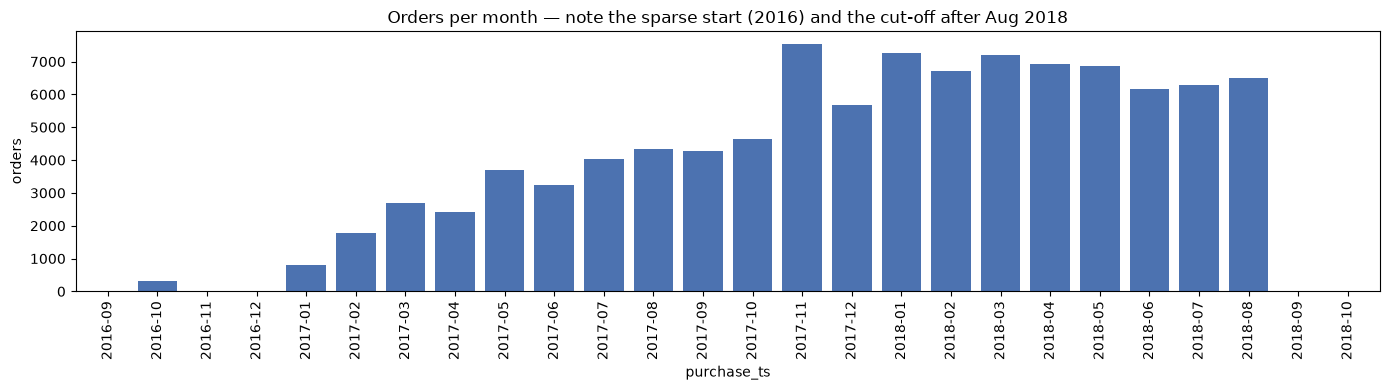

In [7]:
import matplotlib.pyplot as plt
ax = monthly.plot(kind="bar", figsize=(14, 4), color="#4C72B0", width=0.8)
ax.set_xticklabels([d.strftime("%Y-%m") for d in monthly.index], rotation=90)
ax.set_title("Orders per month — note the sparse start (2016) and the cut-off after Aug 2018")
ax.set_ylabel("orders")
plt.tight_layout(); plt.show()

In [8]:
# 3.11 Price / freight outliers (IQR rule) — flag later, never drop
def iqr_bounds(series):
    q1, q3 = series.quantile([.25, .75]); iqr = q3 - q1
    return q1 - 1.5*iqr, q3 + 1.5*iqr

for col in ["price", "freight_value"]:
    lo, hi = iqr_bounds(oi[col])
    n_out = ((oi[col] < lo) | (oi[col] > hi)).sum()
    print(f"{col:14s} IQR upper bound = {hi:8.2f} | outliers = {n_out:6,d} ({n_out/len(oi):.1%}) | max = {oi[col].max():,.2f}")

price          IQR upper bound =   277.40 | outliers =  8,427 (7.5%) | max = 6,735.00
freight_value  IQR upper bound =    33.25 | outliers = 12,134 (10.8%) | max = 409.68


## 4. Cleaning plan for `02_cleaning.ipynb`

| Issue | Fix | Rationale |
|---|---|---|
| Timestamps stored as strings | `pd.to_datetime` on all 8 timestamp columns | Needed for delivery-days and time-series work. |
| Duplicate review rows / multiple reviews per order | Keep the latest `review_answer_timestamp` per `order_id` | One review per order avoids inflating review counts when joining to items. |
| Geolocation duplicates (1M rows, ~19k prefixes) | Drop exact duplicates, then aggregate to mean lat/lng per prefix | Enough for mapping; avoids join explosion. |
| Portuguese categories + a few missing translations | Left-join translation table; hand-fill missing ones; fill null category as `unknown` | English labels for the dashboard. |
| Orders with no items / payments | Keep in `orders` (funnel analysis) but they drop out of `fact_order_items` naturally | Only delivered items are revenue. |
| Delivered orders with null delivery date | Keep, but `is_late` = NaN for them | Can't judge lateness without the date. |
| Price / freight outliers | Add `is_price_outlier` flag using IQR | Real sales; flag lets Power BI filter. |
| Sparse 2016 and post-Aug-2018 data | Trim to 2017-01 → 2018-08 for time-series & forecast only | Partial months distort trends. |

## So what (3 bullets)

- The data is genuinely relational and messy: 9 tables, three of which (reviews, geolocation, customers) have key problems that would silently corrupt metrics if joined naively.
- The biggest analytical trap is `customer_id`: it changes every order, so any repeat-purchase metric built on it reads 0%. `customer_unique_id` must be the customer key throughout.
- Only ~97% of orders are delivered; revenue, delivery and review analyses must be restricted to those, while cancellation analysis needs the full set — two filtered views of the same fact table.